# The LGD ladder: OLS, fractional logit, beta, hurdle, boosting and Tobit

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (the workout LGD and the C08 proxy)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- write the specification of each rung of the C08 ladder (OLS, fractional logit, beta, hurdle, gradient boosting, Tobit) and say what its prediction means;
- rebuild a fitted rung from the coefficients committed in the artifact and predict with the engine's `predict_lgd`, so a committed model is re-usable and checkable;
- refit the five engine rungs with `fit_ols`, `fit_fractional_logit`, `fit_beta`, `fit_hurdle` and `fit_tobit` on a sample whose truth is known, and read what each recovers;
- explain why the beta rung depends on an endpoint adjustment, and read the committed sensitivity to it;
- compare the rungs out of time on the six default cohorts of C08, by R-squared, rank correlation and calibration gap, and say what the calibration gap shows that the R-squared does not.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import lgd_models as lm

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Seven committed artifacts of case C08, the loss given default of small-business loans after default. One is the model artifact `models-dc-2007-08.json`, which holds the fitted ladder (the coefficients, the standardisation, the settings). The other six are the variants `dc-2003-06.json` to `dc-2020-23.json`, one per default cohort, which hold each rung's out-of-time results: R-squared, rank correlation, the calibration gap, the calibration by bucket and the engine's test rows.

The design follows the leakage rules of the research. The ladder is fitted once, on the defaults whose charge-off closed strictly before the cutoff of 31 December 2006, and each cohort from 2007 on is a test the fit has never seen. The target is the charge-off proxy of notebook 01, so everything below is a statement about the proxy and not about a workout LGD. The artifacts were baked by an older engine than the installed one, and the next cell prints both versions.

In [2]:
# Open the model artifact and the six cohort variants, and print the versions that baked them
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C08"
models = json.loads((DERIVED / "models-dc-2007-08.json").read_text(encoding="utf-8"))
COHORTS = ["2003-06", "2007-08", "2009-10", "2011-13", "2014-19", "2020-23"]
cohort = {c: json.loads((DERIVED / f"dc-{c}.json").read_text(encoding="utf-8")) for c in COHORTS}
fit = models["fit"]
print("model artifact baked by riskvalidation:", models["provenance"]["riskvalidation_version"], "| installed:", rv.__version__)
print("cohort variants baked by:", sorted({v["provenance"]["riskvalidation_version"] for v in cohort.values()}))
print("training cutoff:", fit["training"]["cutoff_date"], "| defaults fitted:", f"{fit['training']['n_defaults']:,}")
for model in models["model"]:
    d = model["details"]
    print(f"- {model['id']:21s} {model['title']['en']:48s} library: {model['engine']} {model['engine_version']}")

model artifact baked by riskvalidation: 0.6.0 | installed: 0.8.1
cohort variants baked by: ['0.6.0']
training cutoff: 2006-12-31 | defaults fitted: 48,833
- L1-ols                OLS, clipped to [0, 1]                           library: riskvalidation 0.6.0
- L2-fractional-logit   Fractional logit (quasi-likelihood)              library: riskvalidation 0.6.0
- L3-beta               Beta regression on the endpoint-adjusted LGD     library: riskvalidation 0.6.0
- L4-hurdle             Two-stage hurdle (loss or not, then severity)    library: riskvalidation 0.6.0
- L5-gradient-boosted   Gradient-boosted trees (catboost, cross-entropy) library: catboost 1.2.10
- L6-tobit              Two-limit Tobit                                  library: riskvalidation 0.6.0


## Method

### Step 1: the six rungs and what each predicts

All six rungs predict the mean LGD of a loan given its covariates $x$ (the logarithm of the amount and of the term, the guaranteed and seasoning shares, a revolver flag and the sector dummies), with an intercept column. The engine's `lgd_models` module implements five of them in pure NumPy and SciPy; the sixth is the pipeline's gradient-boosted challenger.

| Rung | Specification | Prediction |
|---|---|---|
| L1 OLS | $y = x'\beta + \varepsilon$ | $\hat y = \min(\max(x'\beta, 0), 1)$, clipped only at prediction |
| L2 fractional logit | $E[y \mid x] = 1 / (1 + e^{-x'\beta})$, Bernoulli quasi-likelihood (Papke and Wooldridge 1996) | $\hat y = 1 / (1 + e^{-x'\beta})$ |
| L3 beta | $y \sim \mathrm{Beta}(\mu\varphi, (1-\mu)\varphi)$, $\mu = 1 / (1 + e^{-x'\beta})$, $\mathrm{Var}(y) = \mu(1-\mu)/(1+\varphi)$ (Ferrari and Cribari-Neto 2004), fitted on $\min(\max(y, \epsilon), 1-\epsilon)$ | $\hat y = \mu$ |
| L4 hurdle | stage 1: $P(y>0 \mid x) = 1/(1+e^{-x'\gamma})$; stage 2: $E[y \mid y>0, x] = 1/(1+e^{-x'\delta})$ among the loans with $y > 0$ (Leow and Mues 2012; Tong, Mues and Thomas 2013) | $\hat y = P(y>0 \mid x)\,E[y \mid y>0, x]$ |
| L5 gradient boosted | CatBoost with the cross-entropy loss, 200 trees of depth 6 | the model's output, in [0, 1] |
| L6 Tobit | $y = \min(1, \max(0, y^*))$, $y^* = x'\beta + \varepsilon$, $\varepsilon \sim N(0, \sigma^2)$ (Tobin 1958) | $E[y \mid x]$ of the censored normal, in closed form |

(Sources: the docstrings of `riskvalidation.lgd_ead.lgd_models` at release 0.8.1, which name the authors above; the gradient-boosting settings are read from the artifact in step 2.) Two properties matter for what follows. OLS can predict outside [0, 1], so its prediction is clipped, which is a choice of the engine. The beta rung cannot take the values 0 and 1 exactly, so it needs the endpoint adjustment $\epsilon$ of step 4. The cell below lists the rungs of the artifact.

In [3]:
# List the rungs of the artifact with their kind and library, and the settings of the boosted rung
for rung in fit["ladder"]:
    print(f"{rung['rung_id']:21s} kind: {rung['kind']:17s} library: {rung['library']} {rung['library_version']} | covariates: {len(rung['covariates'])} | coefficients: {len(rung['coefficients'])}")
boosted = next(m for m in models["model"] if m["id"] == "L5-gradient-boosted")["details"]
print("settings of L5:", boosted["settings"])
top = sorted(boosted["feature_importance"].items(), key=lambda kv: -kv[1])[:5]
print("five most important features of L5:", [(k, round(v, 1)) for k, v in top])

L1-ols                kind: ols               library: riskvalidation 0.6.0 | covariates: 16 | coefficients: 17
L2-fractional-logit   kind: fractional-logit  library: riskvalidation 0.6.0 | covariates: 16 | coefficients: 17
L3-beta               kind: beta              library: riskvalidation 0.6.0 | covariates: 16 | coefficients: 17
L4-hurdle             kind: hurdle            library: riskvalidation 0.6.0 | covariates: 16 | coefficients: 17
L5-gradient-boosted   kind: gradient-boosted  library: catboost 1.2.10 | covariates: 16 | coefficients: 0
L6-tobit              kind: tobit             library: riskvalidation 0.6.0 | covariates: 16 | coefficients: 17
settings of L5: {'iterations': 200, 'depth': 6, 'learning_rate': 0.1, 'l2_leaf_reg': 3.0, 'loss_function': 'CrossEntropy', 'thread_count': 1}
five most important features of L5: [('seasoning_share', 29.4), ('log_term', 23.1), ('log_amount', 17.6), ('guaranteed_share', 16.5), ('revolver', 9.9)]


### Step 2: the committed coefficients

A linear rung is its coefficients plus the standardisation of its four continuous covariates (each is centred and scaled with the mean and standard deviation of the training slice, so that the coefficients are comparable). The artifact keeps both. The cell prints the fractional-logit coefficients beside the OLS ones, and the standardisation. A coefficient on a standardised covariate is the change of the linear predictor per standard deviation; the revolver flag and the sector dummies enter as 0 or 1.

In [4]:
# Print the OLS and fractional-logit coefficients side by side, and the standardisation of the continuous covariates
ladder = {r["rung_id"]: r for r in fit["ladder"]}
detail = {m["id"]: m["details"] for m in models["model"]}
ols_c = {c["name"]: c["estimate"] for c in ladder["L1-ols"]["coefficients"]}
flogit_c = {c["name"]: c["estimate"] for c in ladder["L2-fractional-logit"]["coefficients"]}
print(f"{'term':44s} {'L1 OLS':>10s} {'L2 fractional logit':>24s}")
for term in ols_c:
    print(f"{term:44s} {ols_c[term]:10.4f} {flogit_c[term]:24.4f}")
print()
standard = detail["L2-fractional-logit"]["standardisation"]
for name, s in standard.items():
    print(f"standardisation of {name:18s} mean {s['mean']:8.4f}  standard deviation {s['std']:7.4f}")
print("defaults fitted:", f"{detail['L2-fractional-logit']['n_fitted']:,}", "| left out for a proxy outside [0, 1], counted and never clipped:", f"{detail['L2-fractional-logit']['n_out_of_range_left_out']:,}")

term                                             L1 OLS      L2 fractional logit
const                                            0.6310                   0.5739
log_amount                                      -0.0742                  -0.3781
log_term                                        -0.0132                  -0.0459
guaranteed_share                                -0.0349                  -0.1798
seasoning_share                                 -0.0789                  -0.3748
revolver                                         0.1040                   0.7434
sector_agriculture                              -0.0388                  -0.1261
sector_mining-utilities-construction             0.0149                   0.0698
sector_manufacturing                             0.0339                   0.1756
sector_wholesale                                 0.0370                   0.1918
sector_retail                                    0.0168                   0.0802
sector_transport            

### Step 3: predict with the engine from the committed coefficients

The engine's `LgdFit` holds exactly what the artifact stores, so a committed rung can be rebuilt and used: `LgdFit(kind, names, coefficients, extras)`. The extras are the beta precision $\varphi$ and endpoint $\epsilon$, the two hurdle coefficient vectors, and the Tobit $\sigma$. `predict_lgd(fit, X)` then returns the prediction, with only the OLS one clipped.

The next cell builds the design matrix of three invented loans (a small revolving line in retail, a mid-size manufacturing loan, a large long-term agricultural loan) by applying the committed standardisation, rebuilds five rungs and prints their predictions, followed by the two stages of the hurdle rung. The covariate values are made up to illustrate the arithmetic; they are not loans of the file.

In [5]:
# Build the design matrix of three invented loans, rebuild five committed rungs as LgdFit objects and predict
covariates = ladder["L2-fractional-logit"]["covariates"]
invented = [  # amount, term in months, guaranteed share, seasoning share, revolver, sector
    ("small revolving line, retail", 50_000, 24, 0.50, 0.30, 1, "retail"),
    ("mid-size term loan, manufacturing", 350_000, 84, 0.75, 1.00, 0, "manufacturing"),
    ("large long-term loan, agriculture", 1_500_000, 240, 0.75, 1.00, 0, "agriculture"),
]
rows = []
for _, amount, term, guaranteed, seasoning, revolver, sector in invented:
    raw = {"log_amount": np.log(amount), "log_term": np.log(term), "guaranteed_share": guaranteed, "seasoning_share": seasoning}
    row = [1.0]
    for name in covariates:
        if name in raw:
            row.append((raw[name] - standard[name]["mean"]) / standard[name]["std"])
        elif name == "revolver":
            row.append(float(revolver))
        else:
            row.append(1.0 if name == f"sector_{sector}" else 0.0)
    rows.append(row)
X = np.array(rows)
names = ("const", *covariates)
vec = lambda rung_id: np.array([c["estimate"] for c in ladder[rung_id]["coefficients"]])
hurdle = detail["L4-hurdle"]
rebuilt = {
    "L1 OLS": lm.LgdFit("ols", names, vec("L1-ols")),
    "L2 fractional logit": lm.LgdFit("fractional-logit", names, vec("L2-fractional-logit")),
    "L3 beta": lm.LgdFit("beta", names, vec("L3-beta"), {"phi": detail["L3-beta"]["phi"], "epsilon": ladder["L3-beta"]["epsilon"]}),
    "L4 hurdle": lm.LgdFit("hurdle", names, vec("L4-hurdle"), {"stage1_coefficients": np.array(hurdle["stage1_coefficients"]), "severity_columns": tuple(hurdle["severity_columns"])}),
    "L6 Tobit": lm.LgdFit("tobit", names, vec("L6-tobit"), {"sigma": detail["L6-tobit"]["sigma"]}),
}
print(f"{'':40s} " + " ".join(f"{label:>10s}" for label in ("loan 1", "loan 2", "loan 3")))
for label, f in rebuilt.items():
    print(f"{label:40s} " + " ".join(f"{p:10.4f}" for p in lm.predict_lgd(f, X)))
stage1 = 1 / (1 + np.exp(-(X @ np.array(hurdle["stage1_coefficients"]))))
stage2 = 1 / (1 + np.exp(-(X @ vec("L4-hurdle"))))
print(f"{'hurdle stage 1: P(y > 0)':40s} " + " ".join(f"{p:10.4f}" for p in stage1))
print(f"{'hurdle stage 2: E[y | y > 0]':40s} " + " ".join(f"{p:10.4f}" for p in stage2))
print(f"{'stage 1 times stage 2':40s} " + " ".join(f"{p:10.4f}" for p in stage1 * stage2))

                                             loan 1     loan 2     loan 3
L1 OLS                                       0.9467     0.5396     0.3590
L2 fractional logit                          0.9127     0.5328     0.3326
L3 beta                                      0.9057     0.5363     0.3424
L4 hurdle                                    0.9126     0.5332     0.3287
L6 Tobit                                     0.8972     0.5369     0.3596
hurdle stage 1: P(y > 0)                     1.0000     0.9948     0.9768
hurdle stage 2: E[y | y > 0]                 0.9127     0.5360     0.3365
stage 1 times stage 2                        0.9126     0.5332     0.3287


The five rungs agree on the ordering of the three loans, and they differ most on the first, which sits near the top of the range. That is where the choice of the link matters: OLS gives 0.9467 and the Tobit expectation 0.8972, with the logistic forms between them. The last three rows reproduce the engine's hurdle prediction by hand from its two stages; stage 1 is close to 1, that is, when nearly every default loses something the "loss or not" stage carries little information and the hurdle stays close to the fractional logit.

### Step 4: the endpoint adjustment of the beta rung

The beta density is zero or infinite at 0 and 1, so the beta rung is fitted on $y_\epsilon = \min(\max(y, \epsilon), 1-\epsilon)$, which `endpoint_transform(y, epsilon)` computes. Qi and Zhao (2011), as the engine's docstring records, found beta results very sensitive to this small number, and C08 reports the sensitivity instead of hiding it: `outputs.endpoint_sensitivity` holds, for three values of $\epsilon$, the mean prediction and the RMSE on the cohort. The cell applies the transform to five values and prints the committed sensitivity, with the values of $\varphi$ the artifact reports for the three refits.

In [6]:
# Apply the endpoint transform to five values and print the committed sensitivity to epsilon
sample = np.array([0.0, 0.2, 0.5, 0.97, 1.0])
for eps in (0.0001, 0.001, 0.01):
    print(f"epsilon={eps:<7}", lm.endpoint_transform(sample, eps))
print()
sens = cohort["2007-08"]["outputs"]["endpoint_sensitivity"]
print(f"{'epsilon':>8s} {'mean prediction':>26s} {'RMSE':>8s}")
for row in sens:
    print(f"{row['epsilon']:8.4f} {row['mean_predicted']['value']:26.4f} {row['rmse']:8.4f}")
print("beta precision phi of the committed fit (epsilon 0.001):", round(detail["L3-beta"]["phi"], 4))

epsilon=0.0001  [1.000e-04 2.000e-01 5.000e-01 9.700e-01 9.999e-01]
epsilon=0.001   [0.001 0.2   0.5   0.97  0.999]
epsilon=0.01    [0.01 0.2  0.5  0.97 0.99]

 epsilon            mean prediction     RMSE
  0.0001                     0.7568   0.2928
  0.0010                     0.7503   0.2942
  0.0100                     0.7402   0.2970
beta precision phi of the committed fit (epsilon 0.001): 2.7105


The mean prediction of the beta rung moves with $\epsilon$ while the RMSE barely does: a modeller who picks $\epsilon$ for the best RMSE is also picking a level. A validator should ask for the sensitivity and for the calibration gap at the chosen value, which is what steps 7 and 8 look at.

### Step 5: refit the engine rungs on a sample whose truth is known

The committed artifact keeps the fitted coefficients but not the 47,726 training loans (the SBA file is a third-party dataset that is not committed), so the fits cannot be repeated on the real data here. To see the engine's `fit_*` functions work, the next cell generates a small sample in the notebook, **a toy with a known truth, not a case**: 4,000 loans, two covariates, a body of beta-distributed losses, 18% cures at exactly 0 and 8% total losses at exactly 1. Nothing is read from a file and nothing is written; the seed is fixed. It then fits the five engine rungs on the same design and reports the mean prediction, the RMSE against the realised value and the share of the predictions inside [0, 1].

What to look for: the mean of the realised LGD is the target level, and a well-calibrated rung reproduces it. OLS with an intercept and the logistic quasi-likelihood do so by their own estimating equations; the other rungs need not, and the beta rung is fitted on the endpoint-adjusted values.

In [7]:
# Generate a toy sample with a known truth, fit the five engine rungs on it and compare their calibration
rng = np.random.default_rng(20261021)
n = 4000
x1, x2 = rng.normal(size=n), rng.normal(size=n)
Xt = np.column_stack([np.ones(n), x1, x2])
mu = 1 / (1 + np.exp(-(0.4 + 0.8 * x1 - 0.5 * x2)))
body = rng.beta(mu * 4.0, (1 - mu) * 4.0)
y = np.where(rng.random(n) < 0.18, 0.0, np.where(rng.random(n) < 0.08 / 0.82, 1.0, body))
print(f"toy sample: n={n} | share at 0={np.mean(y == 0):.3f} | share at 1={np.mean(y == 1):.3f} | mean realised LGD={y.mean():.4f}")

toy = {
    "L1 OLS": lm.fit_ols(Xt, y),
    "L2 fractional logit": lm.fit_fractional_logit(Xt, y),
    "L3 beta (epsilon 0.001)": lm.fit_beta(Xt, y, 0.001),
    "L4 hurdle": lm.fit_hurdle(Xt, y),
    "L6 Tobit": lm.fit_tobit(Xt, y),
}
print(f"{'':40s} {'mean prediction':>24s} {'RMSE':>8s} {'R-squared':>12s}")
for label, f in toy.items():
    p = lm.predict_lgd(f, Xt)
    r2 = 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)
    print(f"{label:40s} {p.mean():24.4f} {np.sqrt(np.mean((y - p) ** 2)):8.4f} {r2:12.4f}")
print("beta: precision phi:", round(toy["L3 beta (epsilon 0.001)"].extras["phi"], 4), "| Tobit sigma:", round(toy["L6 Tobit"].extras["sigma"], 4))

toy sample: n=4000 | share at 0=0.167 | share at 1=0.083 | mean realised LGD=0.5217
                                                  mean prediction     RMSE    R-squared
L1 OLS                                                     0.5217   0.3272       0.1480
L2 fractional logit                                        0.5217   0.3270       0.1486
L3 beta (epsilon 0.001)                                    0.4881   0.3342       0.1109
L4 hurdle                                                  0.5219   0.3272       0.1479
L6 Tobit                                                   0.5033   0.3291       0.1379
beta: precision phi: 0.8141 | Tobit sigma: 0.4205


OLS, the fractional logit and the hurdle are tied on R-squared (0.1479 to 0.1486) and on the mean prediction (0.5217 to 0.5219, the realised mean), while the beta rung (0.4881) and the Tobit expectation (0.5033) miss the level: the same lesson as in C08, in a setting where the truth is known. Now the sensitivity of the beta rung to $\epsilon$ on this toy, refitting three times, and the cure decomposition of the research, $E[LGD] = P_{cure}\,LGD_{cure} + (1 - P_{cure})\,LGD_{liq}$, which `cure_decomposition` computes (the practitioner decomposition; the engine marks its single academic source UNVERIFIED, so the notebook states the identity and cites no author). The two cells below use the toy sample and invented probabilities.

In [8]:
# Refit the beta rung at three values of epsilon on the toy sample, and apply the cure decomposition to invented inputs
print(f"realised mean on the toy: {y.mean():.4f}")
for eps in (0.0001, 0.001, 0.01):
    f = lm.fit_beta(Xt, y, eps)
    print(f"epsilon={eps:<7} mean prediction {lm.predict_lgd(f, Xt).mean():.4f}  phi {f.extras['phi']:.4f}")
p_cure = np.array([0.30, 0.50])
print("cure decomposition for P_cure = 0.30 and 0.50 (LGD_cure 0.05 and 0.10, LGD_liq 0.60 and 0.70):", lm.cure_decomposition(p_cure, np.array([0.05, 0.10]), np.array([0.60, 0.70])))

realised mean on the toy: 0.5217
epsilon=0.0001  mean prediction 0.4776  phi 0.6375
epsilon=0.001   mean prediction 0.4881  phi 0.8141
epsilon=0.01    mean prediction 0.5022  phi 1.1691
cure decomposition for P_cure = 0.30 and 0.50 (LGD_cure 0.05 and 0.10, LGD_liq 0.60 and 0.70): [0.435 0.4  ]


### Step 6: out of time, on the six cohorts

Back to the real ladder. Each cohort variant holds `outputs.rung_comparison`, the out-of-time scores of every rung on that cohort: R-squared, RMSE, MAE, Spearman rank correlation and the calibration gap (the mean realised proxy minus the mean predicted). The cell prints a table by cohort. A rung that could not be evaluated on a cohort carries a `reason` instead of numbers, and the cell prints it. The calibration gap is a figure the research and the engine's tests point to beside the R-squared, because R-squared is low for every LGD model (Loterman et al. 2012, as the engine's docstring reports, found average R-squared between 4% and 43%).

In [9]:
# Print R-squared, Spearman and the calibration gap of every rung on each of the six cohorts, and say which rung is best by each criterion
table = {}
for c in COHORTS:
    o = cohort[c]["outputs"]
    print(f"cohort {c} (n={o['lgd_distribution']['n']:,}, mean proxy {o['lgd_distribution']['mean']['value']:.4f})")
    print(f"  {'':22s} {'R-squared':>12s} {'Spearman':>9s} {'calibration gap':>26s}")
    for r in o["rung_comparison"]:
        print(f"  {r['rung_id']:22s} {r['r2']:12.4f} {r['spearman']:9.4f} {r['calibration_gap']:26.4f}")
        table[(c, r["rung_id"])] = (r["r2"], r["calibration_gap"])
    missing = [m["id"] for m in cohort[c]["model"] if m["id"] not in {r["rung_id"] for r in o["rung_comparison"]}]
    for rung_id in missing:
        note = next(t["notes"] for t in cohort[c]["tests"] if t["model_id"] == rung_id)
        print(f"  {rung_id:22s} absent from the comparison; the engine's message, quoted: {note}")

print()
print(f"{'cohort':10s} {'best R-squared':>24s} {'smallest absolute gap':>34s}")
same = 0
for c in COHORTS:
    in_c = {k[1]: v for k, v in table.items() if k[0] == c}
    best_r2 = max(in_c, key=lambda k: in_c[k][0])
    best_gap = min(in_c, key=lambda k: abs(in_c[k][1]))
    same += best_r2 == best_gap
    print(f"{c:10s} {best_r2:>24s} {best_gap:>34s}")
positive = sum(v[1] > 0 for v in table.values())
print(f"cohorts where the best R-squared is also the best calibrated: {same} of {len(COHORTS)} | rung-cohort pairs with a positive gap (realised above predicted): {positive} of {len(table)}")

cohort 2003-06 (n=21,919, mean proxy 0.7081)
                            R-squared  Spearman            calibration gap
  L1-ols                       0.2165    0.5920                     0.0293
  L2-fractional-logit          0.2143    0.5927                     0.0350
  L3-beta                      0.1990    0.5863                     0.0473
  L4-hurdle                    0.2152    0.5939                     0.0350
  L5-gradient-boosted          0.2497    0.6391                     0.0342
  L6-tobit                     0.2044    0.5925                     0.0453
cohort 2007-08 (n=25,299, mean proxy 0.8178)
                            R-squared  Spearman            calibration gap
  L1-ols                       0.1985    0.6305                     0.0491
  L2-fractional-logit          0.2013    0.6301                     0.0530
  L3-beta                      0.1797    0.6363                     0.0675
  L4-hurdle                    0.2015    0.6302                     0.0531
  L5-gradi

### Step 7: calibration by bucket and the engine's tests

The mean can be right while the shape is wrong, so each cohort also holds `calibration_by_bucket`: the loans of the cohort are cut into five equal groups by predicted LGD, and for each group the mean predicted and the mean realised value. A well-calibrated rung lies on the diagonal. The cell draws the 2007-08 cohort for the fractional-logit rung and the boosted rung. It then prints the engine's own test rows for the cohort, committed in `tests`: `lgd_calibration_by_segment` (a paired t-test of the mean gap), `lgd_discrimination` (the Spearman correlation against fixed gates) and `lgd_calibration_over_time` (the paired test per period, Bonferroni-adjusted), each with its light and the baked engine version. The tests are the engine's functions of notebook 06; this notebook only reads their rows.

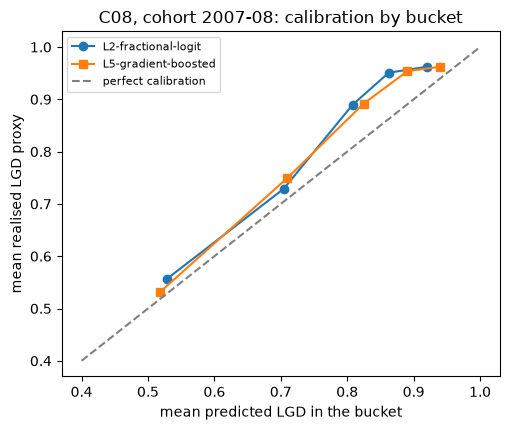

baked by riskvalidation: 0.6.0
lgd_ead.lgd_calibration_by_segment   L2-fractional-logit   red     metric 0.0530  p 2.78e-188
lgd_ead.lgd_discrimination           L2-fractional-logit   green   metric 0.6301  p 0
lgd_ead.lgd_calibration_over_time    L2-fractional-logit   red     metric 0.0748  p 8.61e-147
lgd_ead.lgd_calibration_by_segment   L5-gradient-boosted   red     metric 0.0413  p 8.58e-121
lgd_ead.lgd_discrimination           L5-gradient-boosted   green   metric 0.6762  p 0
lgd_ead.lgd_calibration_over_time    L5-gradient-boosted   red     metric 0.0947  p 6.23e-219


In [10]:
# Draw the calibration by bucket of two rungs and print the engine's test rows committed for the cohort 2007-08
o = cohort["2007-08"]["outputs"]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
for rung_id, marker in (("L2-fractional-logit", "o"), ("L5-gradient-boosted", "s")):
    rows_b = [b for b in o["calibration_by_bucket"] if b["rung_id"] == rung_id]
    ax.plot([b["predicted"]["value"] for b in rows_b], [b["realised"]["value"] for b in rows_b], marker=marker, label=rung_id)
ax.plot([0.4, 1.0], [0.4, 1.0], color="grey", linestyle="--", label="perfect calibration")
ax.set_xlabel("mean predicted LGD in the bucket")
ax.set_ylabel("mean realised LGD proxy")
ax.set_title("C08, cohort 2007-08: calibration by bucket")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
print("baked by riskvalidation:", cohort["2007-08"]["provenance"]["riskvalidation_version"])
for t in cohort["2007-08"]["tests"]:
    if t["model_id"] in ("L2-fractional-logit", "L5-gradient-boosted") and t["test_id"] != "lgd_ead.downturn_coverage":
        p = "n/a" if t["p_value"] is None else f"{t['p_value']:.3g}"
        print(f"{t['test_id']:36s} {t['model_id']:21s} {LIGHT[t['light']]:7s} metric {t['metric']:.4f}  p {p}")

## Results

- **A committed rung is a model you can run.** From the committed coefficients and standardisation alone, `LgdFit` and `predict_lgd` give the fractional logit's LGD for the three invented loans: 0.9127, 0.5328 and 0.3326. The hurdle's two stages multiply back to its own prediction (0.9126, 0.5332 and 0.3287), with stage 1 at 1.0000, 0.9948 and 0.9768.
- **On a known truth, the level separates the rungs, not the R-squared.** On the toy sample the realised mean is 0.5217. OLS, the fractional logit and the hurdle reproduce it (0.5217, 0.5217, 0.5219) with R-squared between 0.1479 and 0.1486, while the beta rung gives 0.4881 and the Tobit expectation 0.5033.
- **The beta rung depends on the endpoint adjustment.** On the committed cohort 2007-08 its mean prediction is 0.7568, 0.7503 and 0.7402 for $\epsilon$ equal to 0.0001, 0.001 and 0.01, while the RMSE moves from 0.2928 to 0.2970. On the toy the same three values give 0.4776, 0.4881 and 0.5022 against a realised mean of 0.5217.
- **Out of time, R-squared is low for every rung, and the best R-squared is not always the best calibration.** Over the 33 rung-cohort scores of step 6, R-squared runs from 0.0975 to 0.2497. The boosted rung has the highest R-squared in all six cohorts and the smallest absolute calibration gap in only 2 of the 6. The gap is positive, the realised proxy above the predicted, in 32 of the 33 scores (the exception is the fractional logit on 2011-13, at -0.0031).
- **The hurdle rung did not run on three cohorts.** For 2009-10, 2011-13 and 2020-23 it is absent from the comparison and its test rows are `not_evaluated`, with the engine's message that the fractional logit did not converge. The artifact records that message and no further cause, and it was baked by engine 0.6.0, so whether 0.8.1 would converge is not known from the committed files.
- **The engine's tests turn the gap into a light.** On 2007-08 the fractional logit (gap 0.0530) and the boosted rung (0.0413) are red on calibration and green on discrimination (Spearman 0.6301 and 0.6762): the ranking works and the level is too low, for a proxy whose bias direction the artifact states.

What the notebook does not do: it does not refit the ladder on the real SBA loans, which are not committed, and it does not name a best rung. The toy sample is generated in the notebook to show the fits and has no relation to any lender.

## Summary

- Six rungs, one target: OLS clipped at prediction, fractional logit (quasi-likelihood), beta on adjusted endpoints, a two-stage hurdle, boosted trees and Tobit. The engine implements five, and the committed artifact stores their coefficients and extras, so any of them can be rebuilt as an `LgdFit` and used with `predict_lgd`.
- On a toy sample with a known truth the R-squared of the rungs is close and their calibration is not; the beta rung moves with the endpoint adjustment, which C08 reports as a sensitivity.
- Out of time, on the six cohorts of C08, the R-squared is low for every rung and the rung with the highest R-squared is the best calibrated in only some cohorts, so the calibration gap is a second criterion. The engine's tests turn the gap into a light with its p-value and the version that baked it.
- Everything here is about the charge-off proxy of C08, not a workout LGD.

**What to try next.** Rebuild the L3 beta rung with the other two values of $\epsilon$ reported in `epsilons_reported` of the artifact and compare its predictions for the three invented loans; then continue with notebook 04, which asks what a downturn does to these LGDs and where the regulatory floors bite.

## References

- Papke, L. E. and Wooldridge, J. M. (1996), the Bernoulli quasi-likelihood for fractional responses (the fractional logit), as named in the engine's documentation of `riskvalidation.lgd_ead.lgd_models`.
- Ferrari, S. L. P. and Cribari-Neto, F. (2004), beta regression with a logit mean link and a log precision link, as named in the same docstring.
- Leow, M. and Mues, C. (2012) and Tong, E. N. C., Mues, C. and Thomas, L. C. (2013), the two-stage (hurdle) LGD model, as named in the docstring of `fit_hurdle`.
- Tobin, J. (1958), the censored normal regression, as named in the docstring of `fit_tobit`.
- Loterman, G., Brown, I., Martens, D., Mues, C. and Baesens, B. (2012), Benchmarking regression algorithms for loss given default modeling, International Journal of Forecasting 28(1). https://doi.org/10.1016/j.ijforecast.2011.01.006
- Qi, M. and Zhao, X. (2011), Comparison of modeling methods for loss given default, Journal of Banking and Finance 35(11). https://doi.org/10.1016/j.jbankfin.2011.03.011
- BCBS, Basel Framework, CRE32 (internal ratings-based approach; the LGD input floors are applied in notebook 04). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- This repository: `docs/design/SDD.md` (case C08) and `data/derived/C08/` (the model artifact and the six cohort variants).